In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import joblib

df = pd.read_csv("churn_cleaned.csv")

df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


### Separate features and target

In [2]:
X = df.drop('Exited', axis=1)
y = df['Exited']

### Identify numerical and categorical columns

In [3]:
numerical_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = X.select_dtypes(include='object').columns.tolist()

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Categorical Features: ['Geography', 'Gender']


### Train-Test Split

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y #preserves the churn distribution.
)

In [5]:
print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (8000, 10)
Testing: (2000, 10)


### Create ColumnTransformer

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)


- ColumnTransformer: Applies different preprocessing to different columns.
- StandardScaler(): Standardizes numerical features.
- OneHotEncoder(): Converts categorical values into numerical columns.
- handle_unknown='ignore': Prevents errors if new, unseen categories appear during prediction.

In [7]:
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

In [8]:
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000, random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        random_state=42, n_jobs=1
    ),

    'SVM': SVC(
        probability=False, random_state=42
    ),

    'KNN': KNeighborsClassifier(),

    'Naive Bayes': GaussianNB(),

    'XGBoost': XGBClassifier(
        eval_metric='logloss',
        random_state=42,
        n_jobs=1
    )
}

In [9]:
pipelines = {}

for name, model in models.items():
    pipelines[name] = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

In [10]:
for name, pipeline in pipelines.items():
    print(name, ":", pipeline)

Logistic Regression : Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['CreditScore', 'Age',
                                                   'Tenure', 'Balance',
                                                   'NumOfProducts', 'HasCrCard',
                                                   'IsActiveMember',
                                                   'EstimatedSalary']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Geography', 'Gender'])])),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])
Decision Tree : Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['CreditScore', 'Age',


In [11]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

baseline_results = {}

for name, pipeline in pipelines.items():

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring='f1',
        n_jobs=1
    )

    baseline_results[name] = scores.mean()

    print(f"{name}: {scores.mean():.4f}")

Logistic Regression: 0.3098
Decision Tree: 0.5082
Random Forest: 0.5683
SVM: 0.5109
KNN: 0.4786
Naive Bayes: 0.4480
XGBoost: 0.5723


In [12]:
pd.Series(baseline_results).sort_values(ascending=False)

XGBoost                0.572273
Random Forest          0.568292
SVM                    0.510896
Decision Tree          0.508202
KNN                    0.478624
Naive Bayes            0.448040
Logistic Regression    0.309818
dtype: float64

## Baseline Model Evaluation

Baseline evaluation means checking how well our machine learning models perform before applying hyperparameter tuning.

In our Customer Churn Prediction project, we have 10,000 records:
- 8,000 records for training.
- 2,000 records for final testing.

We use **3-Fold Cross-Validation** on the 8,000 training records to calculate baseline performance.

### How Does 3-Fold Cross-Validation Work?

1. The 8,000 training records are divided into 3 approximately equal parts (folds).
2. In the first round, two folds are used for training and one for validation.
3. In the second round, a different fold is used for validation.
4. In the third round, the remaining fold is used for validation.
5. The three F1-scores are averaged to get the baseline score.

### Why Do We Calculate Baseline?

- To measure the initial performance of each model.
- To compare different machine learning algorithms.
- To understand how models perform with default parameters.
- To check whether hyperparameter tuning improves model performance.

### Observation

XGBoost achieved the highest baseline F1-score of **0.5723**, followed closely by Random Forest with **0.5683**.

### Conclusion

XGBoost is currently our best-performing baseline model. We will now perform hyperparameter tuning to improve model performance and identify the best model.

**Note:** The 2,000 test records are kept separate and untouched during baseline evaluation and hyperparameter tuning. They will be used only for final model evaluation.

## Hyperparameter Tuning - RandomizedSearchCV

In [13]:
param_grids = {
    'Logistic Regression': {
        'model__C': [0.01, 0.1, 1, 10],
        'model__class_weight': [None, 'balanced']
    },

    'Decision Tree': {
        'model__max_depth': [3, 5, 8, 12, None],
        'model__min_samples_split': [2, 5, 10],
        'model__class_weight': [None, 'balanced']
    },

    'Random Forest': {
        'model__n_estimators': [50, 100, 150],
        'model__max_depth': [5, 8, 12, None],
        'model__min_samples_split': [2, 5, 10]
    },

    'SVM': {
        'model__C': [0.1, 1, 5, 10],
        'model__kernel': ['linear', 'rbf']
    },

    'KNN': {
        'model__n_neighbors': [5, 7, 9, 11],
        'model__weights': ['uniform', 'distance']
    },

    'Naive Bayes': {
        'model__var_smoothing': np.logspace(-11, -7, 5)
    },

    'XGBoost': {
        'model__n_estimators': [50, 100, 150],
        'model__max_depth': [2, 3, 4],
        'model__learning_rate': [0.03, 0.05, 0.1],
        'model__subsample': [0.8, 1.0]
    }
}

In [14]:
from sklearn.model_selection import RandomizedSearchCV

In [15]:
best_models = {}
tuning_results = {}

for name, pipeline in pipelines.items():

    print(f"Tuning {name}...")

    random_search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_grids[name],
        n_iter=5,
        scoring='f1',
        cv=cv,
        random_state=42,
        n_jobs=1
    )

    random_search.fit(X_train, y_train)

    best_models[name] = random_search.best_estimator_

    tuning_results[name] = {
        'Best F1-score': random_search.best_score_,
        'Best Parameters': random_search.best_params_
    }

    print("Best F1-score:", round(random_search.best_score_, 4))
    print("Best Parameters:", random_search.best_params_)
    print("-" * 50)

Tuning Logistic Regression...
Best F1-score: 0.4901
Best Parameters: {'model__class_weight': 'balanced', 'model__C': 0.01}
--------------------------------------------------
Tuning Decision Tree...
Best F1-score: 0.5555
Best Parameters: {'model__min_samples_split': 10, 'model__max_depth': 8, 'model__class_weight': 'balanced'}
--------------------------------------------------
Tuning Random Forest...
Best F1-score: 0.5709
Best Parameters: {'model__n_estimators': 50, 'model__min_samples_split': 5, 'model__max_depth': None}
--------------------------------------------------
Tuning SVM...
Best F1-score: 0.5457
Best Parameters: {'model__kernel': 'rbf', 'model__C': 10}
--------------------------------------------------
Tuning KNN...
Best F1-score: 0.4803
Best Parameters: {'model__weights': 'distance', 'model__n_neighbors': 5}
--------------------------------------------------
Tuning Naive Bayes...
Best F1-score: 0.448
Best Parameters: {'model__var_smoothing': np.float64(1e-11)}
-------------

In [16]:
comparison = pd.DataFrame({
    'Baseline F1': baseline_results,
    'Tuned F1': {
        name: result['Best F1-score']
        for name, result in tuning_results.items()
    }
})

comparison['Improvement'] = (
    comparison['Tuned F1'] - comparison['Baseline F1']
)

comparison = comparison.sort_values(
    by='Tuned F1',
    ascending=False
)

comparison.round(4)

,Baseline F1,Tuned F1,Improvement
XGBoost,0.5723,0.5765,0.0042
Random Forest,0.5683,0.5709,0.0026
Decision Tree,0.5082,0.5555,0.0473
SVM,0.5109,0.5457,0.0348
Logistic Regression,0.3098,0.4901,0.1803
KNN,0.4786,0.4803,0.0017
Naive Bayes,0.4480,0.4480,0.0000


In [17]:
from sklearn.model_selection import cross_validate

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

evaluation_results = {}

for name, model in best_models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    evaluation_results[name] = {
        metric: scores[f'test_{metric}'].mean()
        for metric in scoring
    }

evaluation_df = pd.DataFrame(evaluation_results).T

evaluation_df.round(4)

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.7099,0.3818,0.6847,0.4901,0.7659
Decision Tree,0.7736,0.4633,0.6939,0.5555,0.7990
Random Forest,0.8607,0.7661,0.4552,0.5709,0.8431
SVM,0.8524,0.7302,0.4362,0.5457,0.8129
KNN,0.8291,0.6303,0.3883,0.4803,0.7773
Naive Bayes,0.8115,0.5556,0.3761,0.4480,0.7803
XGBoost,0.8614,0.7625,0.4638,0.5765,0.8631


## Understanding the Important Observations

### XGBoost
- Highest accuracy: **86.14%**.
- Highest F1-score: **0.5765**.
- Highest ROC-AUC: **0.8631**.
- Strong overall performance.

### Random Forest
- Highest precision: **76.61%**.
- Accuracy is very close to XGBoost.
- Recall is **45.52%**.

### Decision Tree
- Recall: **69.39%**, the highest among all seven models.
- However, its precision is relatively low.

### Logistic Regression
- Recall: **68.47%**.
- Its accuracy and F1-score are comparatively low.

## Model Selection Based on Objectives

| Objective | Best Model |
|---|---|
| Highest F1-score | XGBoost |
| Highest ROC-AUC | XGBoost |
| Highest Precision | Random Forest |
| Highest Recall | Decision Tree |
| Highest Accuracy | XGBoost |

### Final Recommendation

**Keep XGBoost as our leading model** because it achieved the highest F1-score, ROC-AUC, and accuracy among all seven models.

In [18]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

# Select the best tuned XGBoost pipeline
final_model = best_models['XGBoost']

# Make predictions on test data
y_pred = final_model.predict(X_test)

# Get churn probabilities for ROC-AUC
y_prob = final_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
final_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_prob)
}

pd.Series(final_metrics).round(4)

Accuracy     0.8655
Precision    0.7875
Recall       0.4644
F1-score     0.5842
ROC-AUC      0.8682
dtype: float64

**What do these results mean?**
- Accuracy (86.55%): Correctly classified approximately 86.55% of test customers.
- Precision (78.75%): Of the customers predicted to leave, 78.75% actually left.
- Recall (46.44%): The model identified 46.44% of all customers who actually left. It missed approximately 53.56% of churners.
- F1-score (58.42%): Balances precision and recall.
- ROC-AUC (86.82%): Shows good ability to distinguish between customers who leave and those who stay.

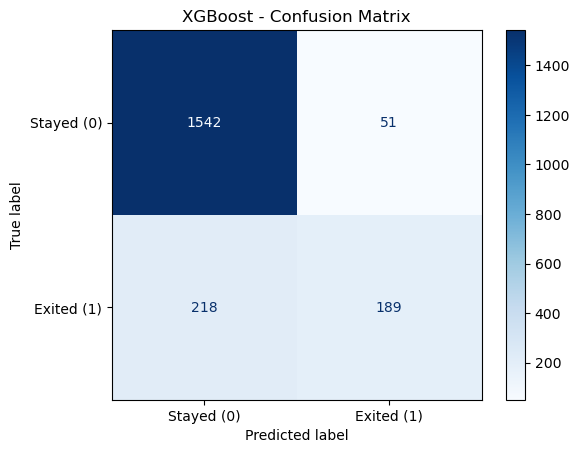

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Stayed (0)', 'Exited (1)']
)

disp.plot(cmap='Blues')
plt.title('XGBoost - Confusion Matrix')
plt.show()

What the numbers tell us
- TN = 1542: Correctly identified 1,542 customers who stayed.
- FP = 51: Incorrectly predicted that 51 customers would leave.
- FN = 218: Failed to identify 218 customers who actually left.
- TP = 189: Correctly identified 189 customers who left.

model is very good at identifying customers who will stay, but it misses a considerable number of customers who are likely to leave.

### Threshold Optimization

In [21]:
from sklearn.model_selection import cross_val_predict

# Generate out-of-fold churn probabilities
y_train_prob = cross_val_predict(
    best_models['XGBoost'],
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=1
)[:, 1]

print("Training probabilities generated:", len(y_train_prob))

Training probabilities generated: 8000


In [22]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.2, 0.3, 0.35, 0.4, 0.45, 0.5]

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (y_train_prob >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_train, y_pred_threshold),
        'Recall': recall_score(y_train, y_pred_threshold),
        'F1-score': f1_score(y_train, y_pred_threshold)
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(4)

,Threshold,Precision,Recall,F1-score
0,0.20,0.4976,0.7521,0.5989
1,0.30,0.6070,0.6387,0.6224
2,0.35,0.6526,0.5969,0.6235
3,0.40,0.6960,0.5534,0.6165
4,0.45,0.7305,0.5055,0.5975
5,0.50,0.7629,0.4638,0.5769


In [23]:
best_threshold = 0.35

# Predict using the selected threshold
y_pred_adjusted = (y_prob >= best_threshold).astype(int)

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

print("Adjusted Threshold:", best_threshold)
print("Accuracy:", round(accuracy_score(y_test, y_pred_adjusted), 4))
print("Precision:", round(precision_score(y_test, y_pred_adjusted), 4))
print("Recall:", round(recall_score(y_test, y_pred_adjusted), 4))
print("F1-score:", round(f1_score(y_test, y_pred_adjusted), 4))

Adjusted Threshold: 0.35
Accuracy: 0.8565
Precision: 0.6587
Recall: 0.6118
F1-score: 0.6344


## 1. Original vs Adjusted XGBoost

| Metric | Original (0.50) | Adjusted (0.35) |
|---|---:|---:|
| Accuracy | 86.55% | 85.65% |
| Precision | 78.75% | 65.87% |
| Recall | 46.44% | 61.18% |
| F1-score | 58.42% | 63.44% |

## 2. What Improved?

- Recall increased by **14.74 percentage points**.
- F1-score increased by **5.02 percentage points**.
- Accuracy decreased slightly by 0.90 percentage points.
- Precision decreased by 12.88 percentage points.

### Business Interpretation

The adjusted model identifies more customers who are likely to leave. However, it also flags more customers who would actually stay.

For a bank trying to retain customers, this can be a worthwhile trade-off.

## 3. Final Model Recommendation


- **Algorithm:** XGBoost
- **Classification Threshold:** 0.35
- **Preprocessing:** StandardScaler + OneHotEncoder
- **Hyperparameter Tuning:** RandomizedSearchCV
- **Cross-Validation:** 3-fold StratifiedKFold

The threshold-adjusted model is our preferred version when balancing precision and recall using F1-score.

In [24]:
import joblib
joblib.dump(final_model, "best_churn_model.pkl")
joblib.dump(best_threshold, "churn_threshold.pkl")

['churn_threshold.pkl']

In [25]:
saved_threshold = joblib.load("churn_threshold.pkl")
print(saved_threshold)

0.35
